# Identificação automática de padrão

A identificação de padrão da tese (regime 6) aplicada ao severe slug: por que não funcionava em dinâmica, as correções e os modos suave e local.

Issues ilustradas (índice em [docs/issues/INDEX.md](../../docs/issues/INDEX.md)):
- [020](../../docs/issues/020-ipe-da-tese-defeitos.md)
- [021](../../docs/issues/021-ipe-suave-e-local.md)

*Nenhuma simulação corre aqui: as corridas vêm de `notebooks/data` (dados históricos, 2026-10)
e dos lotes `batches/*.json` (`mfsim batch`); o notebook só lê e desenha.*

In [1]:
import numpy as np, matplotlib.pyplot as plt, os, json, warnings

warnings.filterwarnings("ignore")
from mfsim.fluid import Fluid
from mfsim.runs import find_run, load_run

fluid = Fluid(rhoL0=900.0, rhoG0=1.2, muL=2e-3, muG=1.8e-5, gammaL=100.0, gammaG=1.05, P0=1e5, sigma=0.05)
D = 0.05
A = np.pi * D**2 / 4
P_out = 4.0
qL = 0.3 * 900 * A
qG = 0.1 * fluid.rhoG((P_out + 1) * 1e5) * A


def datafile(fname):
    """Caminho de uma corrida gravada (notebooks/data ou runs/), ou None se não existir."""
    try:
        return find_run(fname)
    except FileNotFoundError:
        print("trajetória não encontrada:", fname)
        return None


def blowdowns(T_, P_in, min_gap=200.0):
    """Instantes dos blowdowns: mínimos locais da pressão na entrada abaixo de 30 % da
    faixa (separados por pelo menos min_gap s; um blowdown tem mínimos secundários nos
    100 s seguintes). Mais robusto do que contar picos de vazão."""
    lvl = P_in.min() + 0.3 * (P_in.max() - P_in.min())
    low = P_in < lvl
    out = []
    i = 0
    while i < T_.size:
        if low[i]:
            j = i
            while j < T_.size and low[j]:
                j += 1
            k = i + int(np.argmin(P_in[i:j]))
            if not out or T_[k] - out[-1] > min_gap:
                out.append(T_[k])
            i = j
        else:
            i += 1
    return np.array(out)


def cycle_stats(T_, P_in, q_out):
    """(número de blowdowns, período médio entre blowdowns [s], pico máximo de líquido após t = 100 s)."""
    tb = blowdowns(T_, P_in)
    per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
    return tb.size, per, float(q_out[T_ > 100].max())


def load_blocked_run(f):
    """Corrida gravada (partida bloqueada ou linha fechada) pelo carregador único
    `mfsim.runs.load_run` (reconstrói o caso do `meta` com os defaults deste notebook, ou de
    `case_json` nas corridas novas) e os balanços de massa; era uma cópia desta lógica."""
    r = load_run(f)
    return dict(
        meta=r.meta,
        case=r.case,
        model=r.model,
        res=r.res,
        T=r.T,
        p=r.pipe(0),
        ib=r.ib,  # célula no início do joelho
        balL=r.balance("L"),
        balG=r.balance("G"),
        acc=r.acc,  # integral BDF-consistente dos fluxos de contorno
        p_last=r.p_last,  # duto que termina no separador (rede: o último)
        aG_riser_base=r.aG_riser_base(),
    )

## Identificação automática do padrão de escoamento (regime 6)

Até aqui o padrão foi prescrito: estratificado na linha e bolhas no riser, com a
mistura suave por ângulo no joelho. A tese tem uma identificação automática
(`identificaRegimeEstavel.m`): frações de equilíbrio de Taitel–Dukler
(estratificado) e Pots (anular) obtidas por busca em tabela, critérios de
Kelvin–Helmholtz, Jeffreys, Froude e turbulência, e indicadores com chaveamento
sigmoidal de inclinação `k_switch` = 1e6 (degraus). Ela foi portada para JAX
(`closures.regime.equilibrium_fractions`/`identify_regime` com `bk=JAX`, reprodução a 1e−14,
Jacobiana exata) e aplicada ao severe slug.

**O IPE da tese não funciona em dinâmica tal como está.** Nos estados gravados da
corrida de referência ele dá estratificado na linha descendente, intermitente no
trecho horizontal de entrada (a 4 % do limiar de Kelvin–Helmholtz) e "anular" no
riser cheio de líquido (equilíbrio de Pots degenerado com vGS → 0). Na partida
bloqueada o integrador rasteja (9834 passos até 1.5 s; padrão fixo: 101 até 2 s),
por quatro razões, localizadas com saída densa de 1 ms:

1. células cheias de líquido: FG* = FG*c = 0 → sigmoide(0) = 0.5 permanente, e a
   fórmula Int = (1−Est)(1−Anu)(1−Bub) não é partição da unidade (soma 1.44);
2. o gás da entrada inverte o sentido no toque acústico da partida (vGS de +0.5 a
   −0.7 m/s em 0.5 s): com vGS < 0 os equilíbrios dão NaN e o original cai em
   hD = 1e−6 → FG*c salta de 0.02 a 19.8; sign(vM) e aG_bol saltam junto → pesos
   de 0 a 1 em 1 ms, qualquer que seja k;
3. a tabela "mais próxima" muda hD_est em degraus de 2–5 %;
4. `flag_vertical` comparava radianos com 90 (nunca vertical).

**Correções e opções** (numpy e JAX): indicador vertical em graus e partição da
unidade (sem efeito com indicadores 0/1); `low_void_regime` também no modo
automático (bolhas abaixo de 1 %: sem gás não há padrão a identificar);
`ipe_smooth=True`: sigmoides de largura relativa ao valor crítico (`k_switch` ≈ 20,
±10 % do limiar), equilíbrios com |vLS|, |vGS|, hD interpolado na tabela
(contínuo), sentido por tanh(vM/0.02) e aG_bol com módulos. Até 10 s: 170 passos
(k = 20), 427 (k = 50), 370 com padrão fixo. Mas o primeiro *blowdown* continua
caro (13458 passos até 101 s): depois dele fica um bolsão quase parado no joelho
(αG = 0.8, vLS ≈ 0) e o mapa de regime permanente, que só olha velocidades
superficiais, chama-o de "bolhas" sempre que a velocidade do gás, que toca a
~30 Hz, cai; o fechamento alterna bolhas ↔ intermitente a cada 16 ms e sustenta o
toque. `ipe_local=True` avalia os critérios no estado local: nível e fração reais
no lugar dos equilíbrios, fração de bolhas max(aG_bol, αG), estratificado
impossível em dutos verticais e anular acima de αG = 0.9 (filme de parede):
986 passos até 101 s, sem saltos de peso. Abaixo, as corridas completas (3000 s,
mesma malha, arco, conservativa, ν = 0.05, JAX, `tol_range` 0.01) comparadas com
o padrão fixo, e o mapa do padrão identificado ao longo do duto e do tempo.

Resultado: as três variantes do IPE dão o mesmo ciclo de intermitência severa
(4 blowdowns, intervalo 851–883 s contra 765 s com padrão fixo, pressão de
entrada 4.0–5.9 bar nos dois casos, produção média 0.49–0.50 kg/s para
alimentação 0.53), com picos de líquido menores e mais largos (4–5.7 kg/s contra
7.9): no blowdown o riser é identificado como intermitente → anular, com mais
atrito interfacial do que o padrão de bolhas prescrito. O custo é a diferença:
o modo local gasta 35k passos / 207 s de CPU; só o modo suave 163–176k passos /
~32 min (fase rápida a alternar bolhas ↔ intermitente no bolsão do joelho); o
modo da tese (k = 1e6) não passa de t ≈ 2 s. O padrão fixo gasta 26k passos /
50 s (o IPE custa ~3× por passo pelas tabelas de equilíbrio).

In [2]:
from mfsim.closures import identify_regime, equilibrium_fractions

runs_ipe = {}
for tag, fname in (
    ("padrão fixo (estratificado + bolhas no riser)", "severe_slug_blocked_conservative_arc_tol.npz"),
    ("IPE suave (k = 20, bolhas < 1 %)", "severe_slug_blocked_regime6_smooth.npz"),
    ("IPE suave (k = 50, bolhas < 1 %)", "severe_slug_blocked_regime6_smooth_k50.npz"),
    ("IPE suave + critérios no estado local (k = 20)", "severe_slug_blocked_regime6_local.npz"),
):
    f = datafile(fname)
    if f is None:
        print("trajetória não encontrada:", f)
        continue
    runs_ipe[tag] = load_blocked_run(f)


def regime_map(r, step=2):
    """reg2 (1 anular, 2 bolhas, 3 intermitente, 4/5 estratificado) em cada nó e instante gravado."""
    pb_ = r["model"].pipes[0]
    sch_ = pb_.scheme
    mod_ = pb_.model
    T_ = r["T"][::step]
    Ys = r["p"]["Y"][::step]
    reg = np.empty((Ys.shape[1], T_.size))
    for j, Y_ in enumerate(Ys):
        inp_, _, _ = mod_.local_state(Y_, sch_.theta_nodes)
        p_ = mod_.params
        fl_, _ = identify_regime(
            inp_,
            k_switch=p_.k_switch,
            eq=equilibrium_fractions(inp_, smooth=p_.ipe_smooth),
            smooth=p_.ipe_smooth,
            local=p_.ipe_local,
        )
        reg[:, j] = fl_.reg2
    return T_, sch_.x_nodes, reg

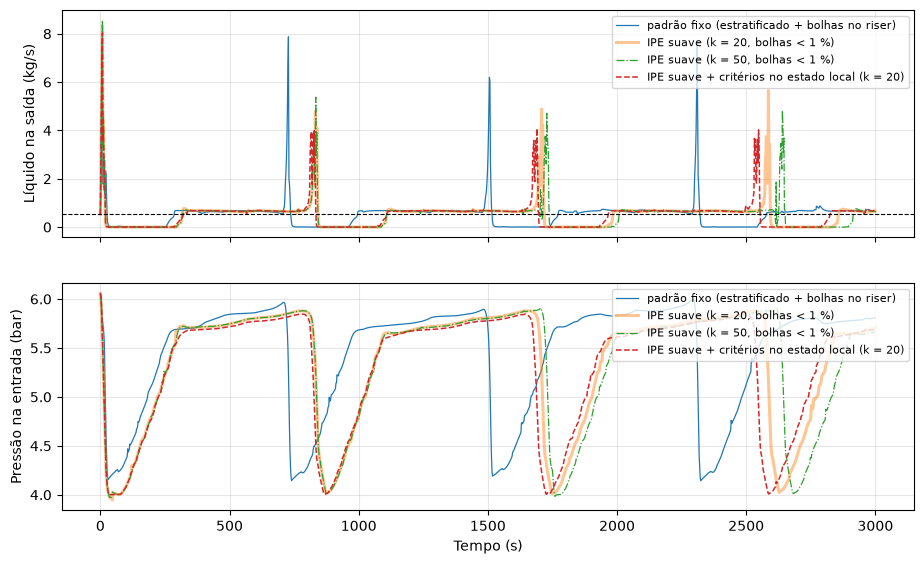

configuração                                     passos    CPU blowdowns intervalo  pico máx   P_in (bar)  erro massa L
padrão fixo (estratificado + bolhas no riser)     25923    50 s         4     765 s    7.9 kg/s  4.14–6.00     +4.3e-05 kg
IPE suave (k = 20, bolhas < 1 %)                 175927  2034 s         4     861 s    5.7 kg/s  4.01–5.88     -2.4e-03 kg
IPE suave (k = 50, bolhas < 1 %)                 163091  1892 s         4     883 s    5.4 kg/s  3.98–5.91     -9.0e-04 kg
IPE suave + critérios no estado local (k = 20)    35328   207 s         4     851 s    4.1 kg/s  4.01–5.86     -2.3e-02 kg


In [3]:
if runs_ipe:
    # estilos distintos: as variantes com k = 20 (suave e suave + local) quase coincidem até o 3º blowdown
    styles = [dict(lw=0.9), dict(lw=2.2, alpha=0.45), dict(lw=0.9, ls="-."), dict(lw=1.1, ls="--")]
    fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
    for (tag, r), st in zip(runs_ipe.items(), styles):
        T_, p_ = r["T"], r["p"]
        axes[0].plot(T_, p_["out"]["qL"][-1], label=tag, **st)
        axes[1].plot(T_, p_["out"]["P_bar"][1], label=tag, **st)
    axes[0].axhline(qL, color="k", ls="--", lw=0.8)
    axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na entrada (bar)")
    axes[1].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="upper right")
    plt.show()
    print(
        f"{'configuração':46s} {'passos':>8s} {'CPU':>6s} {'blowdowns':>9s} {'intervalo':>9s} {'pico máx':>9s} {'P_in (bar)':>12s} {'erro massa L':>13s}"
    )
    for tag, r in runs_ipe.items():
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        massL, _, _ = r["balL"]
        eL = (massL[-1] - massL[0] - r["acc"][0, -1]) if r["acc"] is not None else np.nan
        P1 = r["p"]["out"]["P_bar"][1][T_ > 100]
        print(
            f"{tag:46s} {r['meta']['n_steps']:8d} {r['meta']['cpu']:5.0f} s {nb_:9d} {per:7.0f} s {qmax:6.1f} kg/s {P1.min():5.2f}–{P1.max():4.2f} {eL:+12.1e} kg"
        )

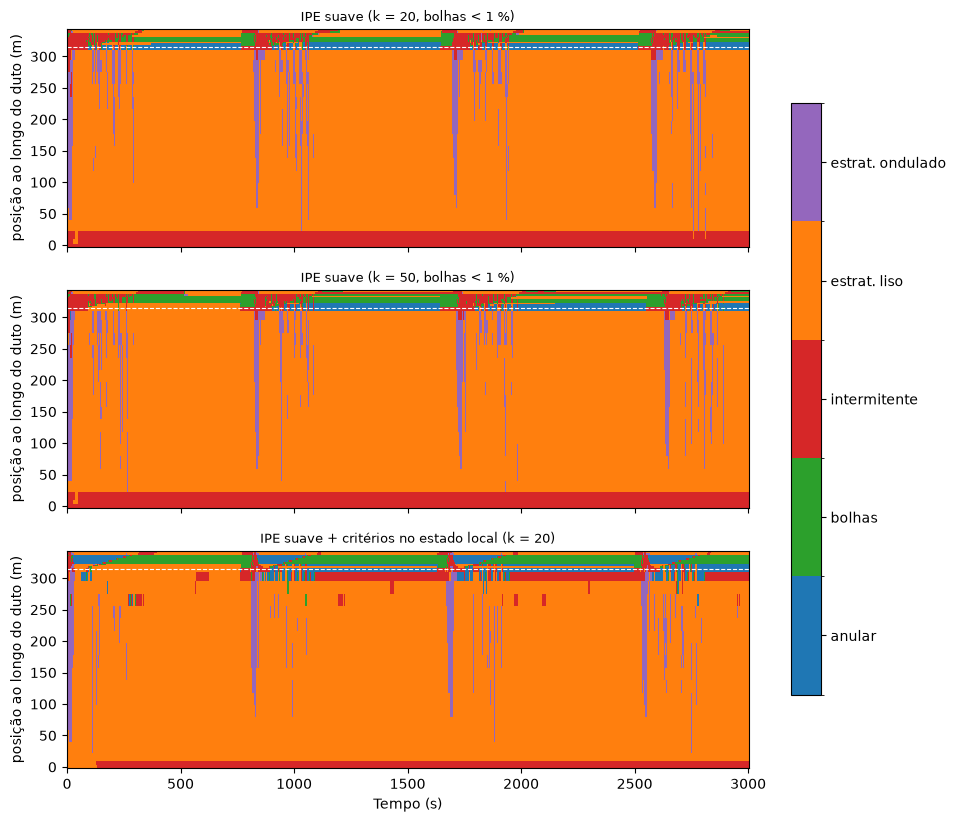

In [4]:
from matplotlib.colors import ListedColormap, BoundaryNorm

ipe_runs = [(t, r) for t, r in runs_ipe.items() if r["meta"].get("regime", 4) == 6]
if ipe_runs:
    cmap = ListedColormap(["#1f77b4", "#2ca02c", "#d62728", "#ff7f0e", "#9467bd"])
    norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5, 5.5], cmap.N)
    fig, axes = plt.subplots(len(ipe_runs), 1, figsize=(11, 3.2 * len(ipe_runs)), sharex=True, squeeze=False)
    for ax, (tag, r) in zip(axes[:, 0], ipe_runs):
        T_, x_, reg = regime_map(r)
        pc = ax.pcolormesh(T_, x_, reg, cmap=cmap, norm=norm, shading="nearest")
        ax.axhline(r["case"].meta["s_elbow0"], color="w", lw=0.8, ls="--")
        ax.set_ylabel("posição ao longo do duto (m)")
        ax.set_title(tag, fontsize=9)
    axes[-1, 0].set_xlabel("Tempo (s)")
    cb = fig.colorbar(pc, ax=axes, ticks=[1, 2, 3, 4, 5], shrink=0.8)
    cb.ax.set_yticklabels(["anular", "bolhas", "intermitente", "estrat. liso", "estrat. ondulado"])
    plt.show()